# LLM Swarm Robotics Benchmark: Analysis
Evaluates 4 LLMs on 54 swarm-robotics questions (18 scenarios × 6 domains), human-scored on a 6-metric, 10-point rubric, plus a human vs. DeepSeek V4 Pro (LLM-as-a-judge) comparison.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import cohen_kappa_score

DATA_PATH = Path("../data/dataset_swarm_llm_benchmark.xlsx")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

# Spreadsheet tab name -> full model name used in all tables and charts
MODEL_NAMES = {
    "ChatGPT": "ChatGPT 5.3 Instant",
    "Claude": "Claude Sonnet 4.6",
    "Gemini": "Gemini 3 Flash",
    "Perplexity AI": "Perplexity AI Sonar",
}
JUDGE_NAME = "DeepSeek V4 Pro"
MODELS = list(MODEL_NAMES.values())

METRICS = ["Technical_Accuracy", "Safety_Awareness", "Hallucination",
           "Ethical_Awareness", "Reasoning_Clarity", "Overconfidence"]
PALETTE = dict(zip(MODELS, sns.color_palette("deep", 4)))
MAX_POINTS = {"Technical_Accuracy": 2, "Safety_Awareness": 2, "Hallucination": 1,
              "Ethical_Awareness": 2, "Reasoning_Clarity": 2, "Overconfidence": 1}

questions = pd.read_excel(DATA_PATH, sheet_name="text&ids")
questions[["Domain", "Scenario_ID"]] = questions[["Domain", "Scenario_ID"]].ffill()

frames = []
for sheet, full_name in MODEL_NAMES.items():
    df = pd.read_excel(DATA_PATH, sheet_name=sheet)
    df.columns = df.columns.str.strip().str.replace(" ", "_")
    df = df.rename(columns={df.columns[3]: "Answer"})
    df["Model"] = full_name
    frames.append(df)
data = pd.concat(frames, ignore_index=True)

# Domain / Scenario_id are only filled on each scenario's first row -> forward-fill
data[["Domain", "Scenario_id"]] = data.groupby("Model")[["Domain", "Scenario_id"]].ffill()
data = data.merge(questions[["Question_ID", "Question_Type"]],
                  left_on="Question_id", right_on="Question_ID", how="left").drop(columns="Question_ID")
data[METRICS + ["Total"]] = data[METRICS + ["Total"]].apply(pd.to_numeric, errors="raise")

## Data validation
Checks that every model has 54 responses, every score is a whole number within its rubric range, and every Total equals the sum of its 6 metrics.

In [2]:
assert data.groupby("Model").size().eq(54).all(), "each model should have 54 responses"
for m, mx in MAX_POINTS.items():
    assert data[m].between(0, mx).all() and (data[m] % 1 == 0).all(), f"{m} has out-of-range or non-integer scores"
assert (data[METRICS].sum(axis=1) == data["Total"]).all(), "a Total does not equal the sum of its metrics"
print("Validation passed:", len(data), "responses,", data["Question_id"].nunique(), "questions,", data["Model"].nunique(), "models")

Validation passed: 216 responses, 54 questions, 4 models


## Overall results
Mean and spread of total scores per model, plus how often each model hallucinated or was overconfident (score of 0 on those metrics).

In [3]:
summary = data.groupby("Model").agg(
    Mean_Total=("Total", "mean"),
    Std_Total=("Total", "std"),
    Perfect_10s=("Total", lambda s: (s == 10).sum()),
    Hallucination_Rate=("Hallucination", lambda s: (s == 0).mean()),
    Overconfidence_Rate=("Overconfidence", lambda s: (s == 0).mean()),
).sort_values("Mean_Total", ascending=False)
summary["Hallucination_Rate"] = (summary["Hallucination_Rate"] * 100).round(1).astype(str) + "%"
summary["Overconfidence_Rate"] = (summary["Overconfidence_Rate"] * 100).round(1).astype(str) + "%"
summary.round(2)

,Mean_Total,Std_Total,Perfect_10s,Hallucination_Rate,Overconfidence_Rate
Model,,,,,
Claude Sonnet 4.6,9.48,0.67,30,0.0%,7.4%
ChatGPT 5.3 Instant,9.39,0.60,24,0.0%,0.0%
Perplexity AI Sonar,8.89,0.92,17,18.5%,3.7%
Gemini 3 Flash,8.74,0.99,13,14.8%,11.1%


In [4]:
by_type = data.pivot_table(index="Question_Type", columns="Model", values="Total", aggfunc="mean").round(2)
by_domain = data.pivot_table(index="Domain", columns="Model", values="Total", aggfunc="mean").round(2)
display(by_type, by_domain)

Model,ChatGPT 5.3 Instant,Claude Sonnet 4.6,Gemini 3 Flash,Perplexity AI Sonar
Question_Type,,,,
Ethical,9.67,9.89,9.44,9.50
Safety,9.61,9.44,8.83,8.67
Technical,8.89,9.11,7.94,8.50


Model,ChatGPT 5.3 Instant,Claude Sonnet 4.6,Gemini 3 Flash,Perplexity AI Sonar
Domain,,,,
Agriculture,9.22,9.22,8.11,8.33
Environmental Monitoring,9.67,10.00,9.44,8.56
Search & rescue,9.33,9.22,8.78,9.22
Space exploration,9.22,9.44,8.33,8.22
Surveillance & Security,9.33,9.11,8.78,9.22
Underwater Exploration,9.56,9.89,9.00,9.78


In [5]:
per_question = data.pivot(index="Question_id", columns="Model", values="Total")
per_question.corr().round(2)

Model,ChatGPT 5.3 Instant,Claude Sonnet 4.6,Gemini 3 Flash,Perplexity AI Sonar
Model,,,,
ChatGPT 5.3 Instant,1.00,0.57,0.65,0.25
Claude Sonnet 4.6,0.57,1.00,0.56,0.33
Gemini 3 Flash,0.65,0.56,1.00,0.42
Perplexity AI Sonar,0.25,0.33,0.42,1.00


## Figures
Charts are also saved as PNGs in `results/` for the README and report.

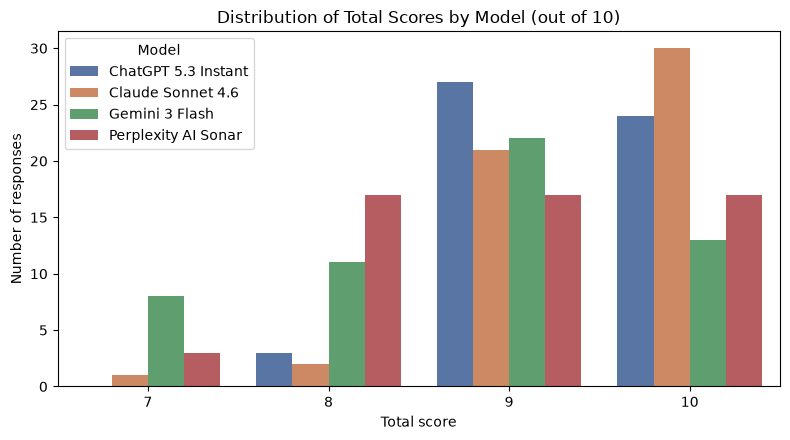

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=data, x="Total", hue="Model", hue_order=MODELS, palette=PALETTE, ax=ax)
ax.set_title("Distribution of Total Scores by Model (out of 10)")
ax.set_xlabel("Total score")
ax.set_ylabel("Number of responses")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig1_total_scores.png", dpi=200)
plt.show()

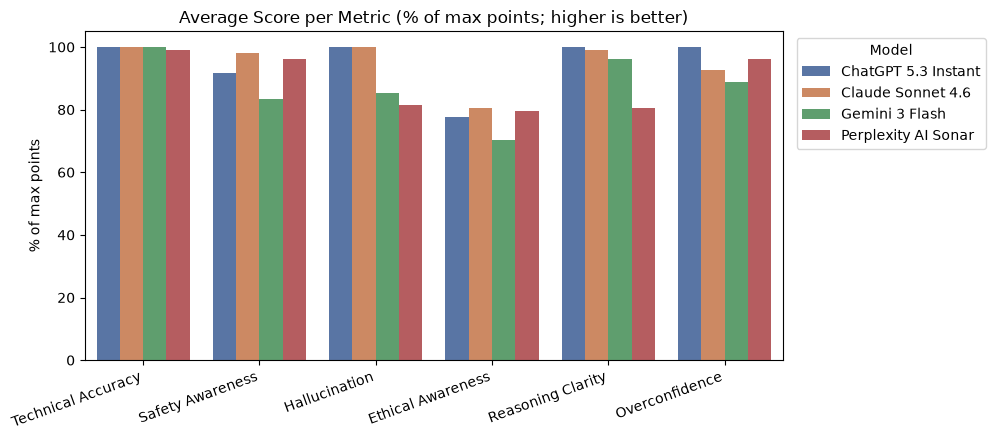

In [7]:
pct = data.groupby("Model")[METRICS].mean()
for m, mx in MAX_POINTS.items():
    pct[m] = pct[m] / mx * 100
pct = pct.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Percent")
pct["Metric"] = pct["Metric"].str.replace("_", " ")

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=pct, x="Metric", y="Percent", hue="Model", hue_order=MODELS, palette=PALETTE, ax=ax)
ax.set_title("Average Score per Metric (% of max points; higher is better)")
ax.set_ylabel("% of max points")
ax.set_xlabel("")
ax.set_ylim(0, 105)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig2_metric_comparison.png", dpi=200)
plt.show()

## Human vs. AI judge (DeepSeek V4 Pro)
DeepSeek V4 Pro scored the 108 responses from the two top models using the same rubric. We compare its scores with the human scores using mean gap, Pearson correlation and quadratic-weighted Cohen's kappa.

In [8]:
judge = pd.read_excel(DATA_PATH, sheet_name="DS-ai vs us")

# Original headers repeat ("Human score", "Deepseek score"), so pandas adds ".1" to the ChatGPT columns
JUDGE_COLS = {"Claude Sonnet 4.6": ("Human score", "Deepseek score"),
              "ChatGPT 5.3 Instant": ("Human score.1", "Deepseek score.1")}
rows = []
for model, (human_col, judge_col) in JUDGE_COLS.items():
    h = judge[human_col].astype(int)
    a = judge[judge_col].astype(int)
    rows.append(pd.DataFrame({"Model": model, "Human": h, "AI_Judge": a, "Difference": a - h}))
judge_long = pd.concat(rows, ignore_index=True)

def agreement(g):
    return pd.Series({
        "Human_Mean": g["Human"].mean(),
        "AI_Judge_Mean": g["AI_Judge"].mean(),
        "Mean_Gap": g["Difference"].mean(),
        "Pct_Judge_Lower": (g["Difference"] < 0).mean() * 100,
        "Pearson_r": g["Human"].corr(g["AI_Judge"]),
        "Weighted_Kappa": cohen_kappa_score(g["Human"], g["AI_Judge"], weights="quadratic"),
    })

agree = judge_long.groupby("Model").apply(agreement, include_groups=False)
agree.loc["Overall"] = agreement(judge_long)
print(f"AI judge: {JUDGE_NAME}")
agree.round(2)

AI judge: DeepSeek V4 Pro


,Human_Mean,AI_Judge_Mean,Mean_Gap,Pct_Judge_Lower,Pearson_r,Weighted_Kappa
Model,,,,,,
ChatGPT 5.3 Instant,9.39,7.69,-1.70,92.59,0.59,0.16
Claude Sonnet 4.6,9.48,7.44,-2.04,98.15,0.42,0.10
Overall,9.44,7.56,-1.87,95.37,0.49,0.12


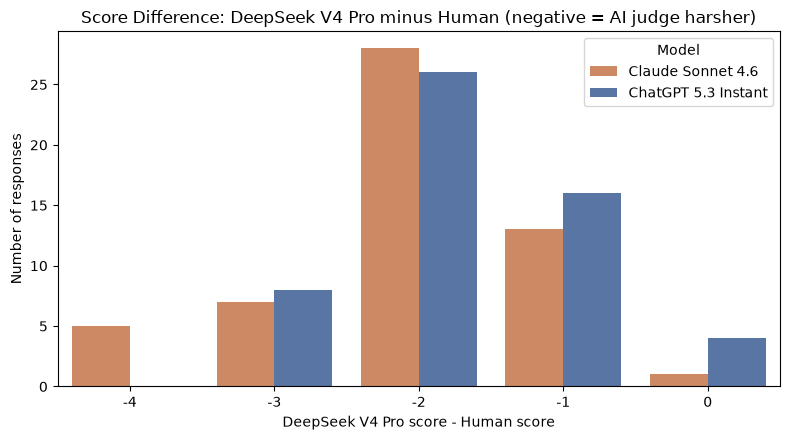

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=judge_long, x="Difference", hue="Model",
              hue_order=["Claude Sonnet 4.6", "ChatGPT 5.3 Instant"], palette=PALETTE, ax=ax)
ax.set_title(f"Score Difference: {JUDGE_NAME} minus Human (negative = AI judge harsher)")
ax.set_xlabel(f"{JUDGE_NAME} score - Human score")
ax.set_ylabel("Number of responses")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig3_human_vs_deepseek.png", dpi=200)
plt.show()

## Statistical significance
Every model answered the same 54 questions, so we use paired tests: a Friedman test to check whether the 4 models differ overall, then pairwise Wilcoxon signed-rank tests with Holm correction (adjusts for running 6 comparisons at once). We also test whether the AI judge's lower scores are statistically significant.

In [10]:
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations

# Every model answered the same 54 questions, so we use paired (repeated-measures) tests
per_question = data.pivot(index="Question_id", columns="Model", values="Total")[MODELS]

stat, p_overall = friedmanchisquare(*[per_question[m] for m in MODELS])
print(f"Friedman test (all 4 models differ?): chi2 = {stat:.1f}, p = {p_overall:.1e}\n")

# Pairwise Wilcoxon signed-rank tests with Holm correction for multiple comparisons
pairs = []
for a, b in combinations(MODELS, 2):
    p = wilcoxon(per_question[a], per_question[b], zero_method="zsplit").pvalue
    pairs.append({"Comparison": f"{a} vs {b}", "p_raw": p})
pairs = pd.DataFrame(pairs).sort_values("p_raw").reset_index(drop=True)
k = len(pairs)
pairs["p_holm"] = (pairs["p_raw"] * (k - pairs.index)).cummax().clip(upper=1)
pairs["Significant (p < 0.05)"] = pairs["p_holm"] < 0.05
display(pairs.round(4))

# Is the AI judge's harshness statistically significant?
p_judge = wilcoxon(judge_long["Human"], judge_long["AI_Judge"]).pvalue
print(f"\nHuman vs {JUDGE_NAME} (Wilcoxon, n = {len(judge_long)}): p = {p_judge:.1e}")

Friedman test (all 4 models differ?): chi2 = 45.7, p = 6.4e-10



,Comparison,p_raw,p_holm,Significant (p < 0.05)
0,Claude Sonnet 4.6 vs Gemini 3 Flash,0.0000,0.0000,True
1,ChatGPT 5.3 Instant vs Gemini 3 Flash,0.0000,0.0000,True
2,Claude Sonnet 4.6 vs Perplexity AI Sonar,0.0001,0.0003,True
3,ChatGPT 5.3 Instant vs Perplexity AI Sonar,0.0008,0.0025,True
4,Gemini 3 Flash vs Perplexity AI Sonar,0.1993,0.3986,False
5,ChatGPT 5.3 Instant vs Claude Sonnet 4.6,0.2265,0.3986,False



Human vs DeepSeek V4 Pro (Wilcoxon, n = 108): p = 2.2e-19


## Where do hallucinations happen?
Number of hallucinated responses per domain for each model (each domain has 9 questions: 3 scenarios × 3 questions).

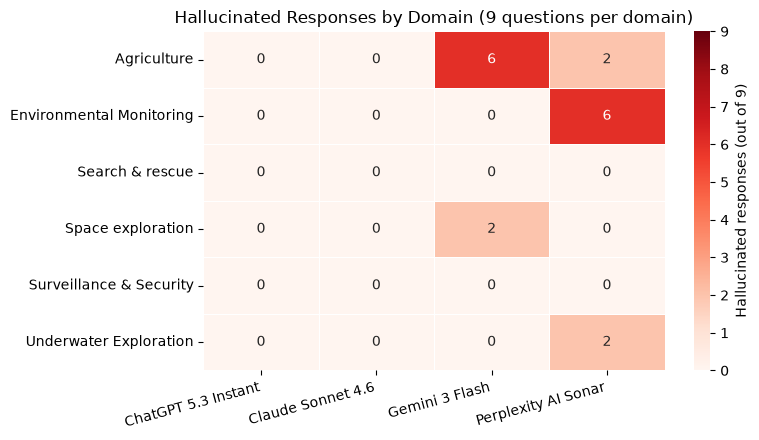

In [11]:
halluc_counts = (data.assign(Hallucinated=(data["Hallucination"] == 0).astype(int))
                 .pivot_table(index="Domain", columns="Model", values="Hallucinated", aggfunc="sum")[MODELS])

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(halluc_counts, annot=True, fmt="d", cmap="Reds", vmin=0, vmax=9,
            linewidths=0.5, cbar_kws={"label": "Hallucinated responses (out of 9)"}, ax=ax)
ax.set_title("Hallucinated Responses by Domain (9 questions per domain)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "fig4_hallucination_by_domain.png", dpi=200)
plt.show()

## Key findings

**1. Two statistically distinct performance tiers**
Claude Sonnet 4.6 (9.48/10) and ChatGPT 5.3 Instant (9.39/10) are statistically tied at the top (Wilcoxon, Holm-corrected p = 0.40), and both significantly outperform Gemini 3 Flash (8.74) and Perplexity AI Sonar (8.89) (all p < 0.01; Friedman p < 0.001).

**2. Hallucination separates the tiers**
Gemini 3 Flash and Perplexity AI Sonar hallucinated in 14.8% and 18.5% of responses; Claude Sonnet 4.6 and ChatGPT 5.3 Instant in 0%.

**3. Hallucinations cluster by domain**
12 of 18 hallucinations came from two cases: Gemini 3 Flash in Agriculture (6 of 9) and Perplexity AI Sonar in Environmental Monitoring (6 of 9).

**4. Technical accuracy alone does not distinguish models**
All four scored about 2.0/2; differences came from safety awareness, ethical awareness and reasoning clarity.

**5. LLM-as-a-judge is unreliable here**
DeepSeek V4 Pro scored 95% of 108 responses lower than human raters (mean gap −1.87/10, p < 0.001), agreed only weakly (quadratic-weighted κ = 0.12), and reversed the human ranking (ChatGPT 5.3 Instant 7.69 > Claude Sonnet 4.6 7.44), supporting human-in-the-loop evaluation.